# Step 2 — Detect objects in a frame (Faster R-CNN)

**Goal:** take one frame, find the objects in it with a pre-trained detector, and draw boxes around the cars / bikes / people.

**The idea:** `Faster R-CNN` (from torchvision, already trained on the COCO dataset) looks at an image and returns, for every object it finds:
- a **box** `(x1, y1, x2, y2)` — the rectangle around it
- a **label** — which COCO class (a number we map to a name)
- a **score** — confidence from 0 to 1

We then **filter**: keep only traffic objects, drop low-confidence ones, keep the strongest 19. Those become object slots 1–19 later.

⚠️ The first run downloads the model (~160 MB) and detection on CPU takes a few seconds — that's normal.

Run each cell with **Shift+Enter**.

## 1. Load one frame (same as Step 1)

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.patches as patches
import torch
import torchvision

VIDEO_PATH = "../Dataset/videos/test/Accident/000456.mp4"
FRAME_INDEX = 50

cap = cv2.VideoCapture(VIDEO_PATH)
frames = []
while True:
    ok, f = cap.read()
    if not ok:
        break
    frames.append(f)
cap.release()

frame_bgr = frames[FRAME_INDEX]
frame_rgb = cv2.cvtColor(frame_bgr, cv2.COLOR_BGR2RGB)   # RGB for the model + display
print("frame shape:", frame_rgb.shape)

frame shape: (720, 1280, 3)


## 2. Load the pre-trained Faster R-CNN
We put it in `eval()` mode (we are only using it, not training it).

In [2]:
from torchvision.models.detection import fasterrcnn_resnet50_fpn

try:
    from torchvision.models.detection import FasterRCNN_ResNet50_FPN_Weights
    model = fasterrcnn_resnet50_fpn(weights=FasterRCNN_ResNet50_FPN_Weights.DEFAULT)
except Exception:
    model = fasterrcnn_resnet50_fpn(pretrained=True)

model.eval()
print("detector loaded.")

Downloading: "https://download.pytorch.org/models/fasterrcnn_resnet50_fpn_coco-258fb6c6.pth" to C:\Users\niles/.cache\torch\hub\checkpoints\fasterrcnn_resnet50_fpn_coco-258fb6c6.pth


A Jupyter Widget

detector loaded.


## 3. Run detection on the frame
The model wants a list of image tensors shaped `(3, H, W)`, float, values `0–1`, RGB order. It does its own normalization internally.

In [3]:
# (H, W, 3) uint8  ->  (3, H, W) float in [0,1]
tensor = torch.from_numpy(frame_rgb).permute(2, 0, 1).float() / 255.0

with torch.no_grad():                 # no training -> no gradients needed
    output = model([tensor])[0]       # one image in, one dict out

boxes  = output["boxes"].numpy()      # (N, 4)  -> x1,y1,x2,y2
labels = output["labels"].numpy()     # (N,)    -> COCO class numbers
scores = output["scores"].numpy()     # (N,)    -> confidence 0..1

print("raw detections:", len(boxes))
print("top 5 scores   :", np.round(scores[:5], 2))

raw detections: 31
top 5 scores   : [0.99 0.99 0.95 0.9  0.78]


## 4. Filter: traffic classes, confident, top 19
COCO gives 80 classes; we only care about road users. `labels` are numbers — we map them to names.

In [10]:
# COCO class numbers we keep (torchvision indexing).
KEEP = {1: "person", 2: "bicycle", 3: "car", 4: "motorcycle",
        6: "bus", 7: "train", 8: "truck"}
SCORE_THRESH = 0.5
MAX_OBJECTS  = 19

kept = []
for box, label, score in zip(boxes, labels, scores):
    if score < SCORE_THRESH:
        continue
    if int(label) not in KEEP:
        continue
    kept.append((score, KEEP[int(label)], box))

kept.sort(key=lambda t: t[0], reverse=True)   # highest score first
kept = kept[:MAX_OBJECTS]                       # cap at 19 object slots

print(f"kept {len(kept)} objects:")
for score, name, box in kept:
    x1, y1, x2, y2 = box.round().astype(int)
    print(f"  {name:10s} score={score:.2f}  box=({x1},{y1},{x2},{y2})")

kept 5 objects:
  car        score=0.99  box=(685,382,750,449)
  car        score=0.99  box=(546,387,588,423)
  car        score=0.95  box=(576,374,698,484)
  truck      score=0.90  box=(149,263,553,529)
  car        score=0.51  box=(704,365,766,400)


## 5. Draw the boxes on the frame (inline)

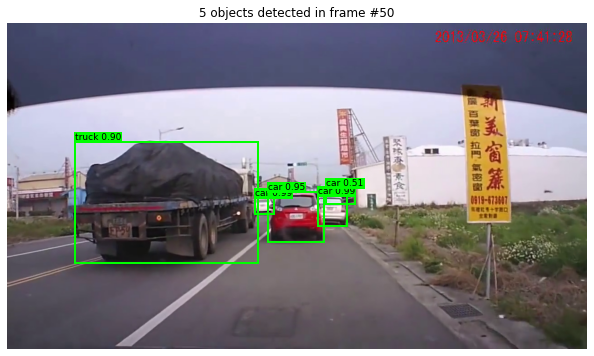

In [11]:
fig, ax = plt.subplots(figsize=(11, 6))
ax.imshow(frame_rgb)
ax.set_title(f"{len(kept)} objects detected in frame #{FRAME_INDEX}")
ax.axis("off")

for score, name, box in kept:
    x1, y1, x2, y2 = box
    rect = patches.Rectangle((x1, y1), x2 - x1, y2 - y1,
                             linewidth=2, edgecolor="lime", facecolor="none")
    ax.add_patch(rect)
    ax.text(x1, y1 - 5, f"{name} {score:.2f}",
            color="black", fontsize=9,
            bbox=dict(facecolor="lime", edgecolor="none", pad=1))

plt.show()

## What to take away
1. A pre-trained detector gives **box + label + score** per object — no training needed.
2. The model wants a `(3, H, W)` float tensor in `[0,1]`, **RGB**.
3. Raw output has many detections; we **filter** by class and score, then **cap at 19** (the number of object slots).
4. These boxes are exactly what we'll crop next and turn into feature vectors.

**Try it:** lower `SCORE_THRESH` to 0.3 (more boxes, some wrong) or raise to 0.8 (fewer, very sure). Change `FRAME_INDEX` to see detection at a different moment — remember to re-run the cells below it (or Restart & Run All).

Next: **Step 3 — turn one cropped object into 4096 numbers with VGG-16.**